# 11floodextract (version 2): December 2021 flood extent from radar, per hexagon

The first version only looked for **dark** water and found almost nothing. `12floodcheck` showed that in built-up areas floodwater makes the radar image **brighter**, and that single pixels are noisy. This version:

1. Flags pixels with two rules: **open water** (dark, darker than on dry days) and **built-up flooding** (at least 3 dB brighter than on dry days, in built-up areas).
2. Does this for the two flood images (20 and 22 Dec) **and for two dry days (8 and 9 Dec) as a control**, with exactly the same method.
3. Adds up, per hexagon, the share of its area flagged on each day.
4. Compares flood days with dry days to choose a fair hexagon threshold, and checks known flooded places.

The old version is kept in the `old` folder.

**How to use this notebook:** run it once with the starting values in Section 0. Read the calibration table in Step 8. Then, if needed, change `CHOSEN_RULE` and `HEX_THRESHOLD` in Section 0 and re-run **only Step 8** (the radar sums are cached, so this takes seconds).

## Section 0: settings

Change numbers here. If you change a radar threshold, the hexagon sums are recalculated automatically (a new cache folder is used). `CHOSEN_RULE` and `HEX_THRESHOLD` only affect Step 8.

In [ ]:
EE_PROJECT = "uhisea"                           # <- your Google Cloud project for Earth Engine
GRID_FILE = "data/processed/hex_grid.parquet"   # <- the Stage 1 hexagons
BOX_MARGIN_DEG = 0.02                           # <- extra space around the hexagons

# Four comparisons. a and b are the flood images, c and d are dry-day controls. Dates are UTC.
EVENTS = [
    {"key": "a", "kind": "flood",    "name": "20 Dec 2021 evening", "after": ["2021-12-20", "2021-12-21"], "before": ["2021-11-10", "2021-12-13"], "orbit": 70},
    {"key": "b", "kind": "flood",    "name": "22 Dec 2021 morning", "after": ["2021-12-21", "2021-12-22"], "before": ["2021-11-10", "2021-12-13"], "orbit": 91},
    {"key": "c", "kind": "baseline", "name": "8 Dec 2021 (dry control)", "after": ["2021-12-08", "2021-12-09"], "before": ["2021-11-10", "2021-12-07"], "orbit": 70},
    {"key": "d", "kind": "baseline", "name": "9 Dec 2021 (dry control)", "after": ["2021-12-09", "2021-12-10"], "before": ["2021-11-10", "2021-12-08"], "orbit": 91},
]

# Pixel rules (VV radar channel, decibels)
SMOOTH_M = 30               # <- speckle filter radius in metres
WATER_MAX_DB = -17.0        # <- open water: darker than this ...
WATER_DROP_DB = 3.0         # <- ... and at least this much darker than on dry days
BRIGHT_DB = 3.0             # <- built-up flooding: at least this much brighter than on dry days
USE_BUILTUP_RULE = True     # <- False = open-water rule only (like version 1)
MIN_CONNECTED = 8           # <- ignore flagged specks smaller than this many pixels

# False alarm filters
PERM_WATER_PCT = 50         # <- ignore places that are water in 50% or more of satellite history
HAND_MAX_M = 15             # <- ignore ground more than this many metres above the nearest drainage
SLOPE_MAX_DEG = 5           # <- ignore ground steeper than this

# Hexagon sums
SUM_SCALE_M = 20            # <- pixel size used when adding up per hexagon
BATCH_SIZE = 250            # <- hexagons per Earth Engine request
MAKE_PREVIEW = True         # <- save two preview pictures in output

# Step 8: the final hexagon decision (re-run only Step 8 after changing these)
CHOSEN_RULE = "both"        # <- "both" = flagged on both flood days, "either" = flagged on at least one day
HEX_THRESHOLD = 0.20        # <- share of the hexagon area that must be flagged (0.20 = 20%)
BASELINE_TOLERANCE = 0.10   # <- Step 8 suggests the lowest threshold where dry days flag at most this share of the flood-day hexagons

# Places to check in Step 8: (name, longitude, latitude, note)
PLACES = [                                                   # <- add or remove places here
    ("Taman Sri Muda (Shah Alam)", 101.5345, 3.0325, "flooded, confirmed"),
    ("Dengkil (Sepang)", 101.6750, 2.8661, "flooded, confirmed"),
    ("Kota Kemuning (Shah Alam)", 101.5107, 3.0229, "not confirmed"),
    ("KLCC (control)", 101.7116, 3.1579, "not flooded"),
]

## Step 1: connect to Earth Engine

In [ ]:
import ee, json, time, hashlib, os
import numpy as np
import pandas as pd
import h3

try:
    ee.Initialize(project=EE_PROJECT)
except Exception as err:
    print("Not logged in yet (" + type(err).__name__ + "). Starting login...")
    ee.Authenticate()
    ee.Initialize(project=EE_PROJECT)
print("Connected to Earth Engine, project:", EE_PROJECT)

Connected to Earth Engine, project: uhisea


## Step 2: the hexagons and the Klang Valley box

In [ ]:
grid = pd.read_parquet(GRID_FILE)
west, east = grid["lon"].min() - BOX_MARGIN_DEG, grid["lon"].max() + BOX_MARGIN_DEG
south, north = grid["lat"].min() - BOX_MARGIN_DEG, grid["lat"].max() + BOX_MARGIN_DEG
region = ee.Geometry.Rectangle([west, south, east, north])

def hex_feature(h):
    ring = [[lng, lat] for lat, lng in h3.cell_to_boundary(h)]
    return ee.Feature(ee.Geometry.Polygon([ring], None, False), {"h3": h})

print(f"{len(grid):,} hexagons, box west {west:.3f}, south {south:.3f}, east {east:.3f}, north {north:.3f}")

4,003 hexagons, box west 101.196, south 2.581, east 101.986, north 3.419


## Step 3: helper layers

Permanent water (JRC), height above the nearest drainage (MERIT Hydro), slope (Copernicus DEM) and built-up land (ESA WorldCover 2021).

In [ ]:
occurrence = ee.Image("JRC/GSW1_4/GlobalSurfaceWater").select("occurrence").unmask(0)
hand = ee.Image("MERIT/Hydro/v1_0_1").select("hnd").unmask(0)

dem_col = None
for dem_id in ["COPERNICUS/DEM/GLO30_2024_1", "COPERNICUS/DEM/GLO30"]:
    col = ee.ImageCollection(dem_id)
    n = col.filterBounds(region).size().getInfo()
    if n > 0:
        dem_col, dem_used = col, dem_id
        break
dem = dem_col.select("DEM").mosaic().setDefaultProjection(dem_col.first().select("DEM").projection())
slope = ee.Terrain.slope(dem).unmask(0)

builtup = ee.ImageCollection("ESA/WorldCover/v200").first().select("Map").eq(50).unmask(0)
ok_ground = hand.lte(HAND_MAX_M).And(slope.lte(SLOPE_MAX_DEG)).And(occurrence.lt(PERM_WATER_PCT))
print("Elevation data used:", dem_used, f"({n} tiles over the box); built-up layer: ESA WorldCover 2021")

Elevation data used: COPERNICUS/DEM/GLO30_2024_1 (362 tiles over the box); built-up layer: ESA WorldCover 2021


## Step 4: pixel flags for all four comparisons

Each comparison gets three flag layers: `W` (open water), `U` (built-up flooding) and `F` (either one, specks removed). Flood days and dry controls go through exactly the same code.

In [ ]:
def s1_collection(start, end, orbit):
    return (ee.ImageCollection("COPERNICUS/S1_GRD")
            .filterBounds(region).filterDate(start, end)
            .filter(ee.Filter.eq("instrumentMode", "IW"))
            .filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VV"))
            .filter(ee.Filter.eq("relativeOrbitNumber_start", orbit))
            .select("VV"))

def smooth(img):
    return img.focal_median(SMOOTH_M, "circle", "meters")

layers = {}
for ev in EVENTS:
    a_col = s1_collection(ev["after"][0], ev["after"][1], ev["orbit"])
    b_col = s1_collection(ev["before"][0], ev["before"][1], ev["orbit"])
    print(f"{ev['key']}  {ev['name']}: {a_col.size().getInfo()} image slices after, {b_col.size().getInfo()} before (orbit {ev['orbit']})")
    after = smooth(a_col.mosaic())
    before = smooth(b_col.median())
    change = after.subtract(before)
    observed = after.mask().And(before.mask())
    water = after.lt(WATER_MAX_DB).And(change.lt(-WATER_DROP_DB)).And(before.gte(WATER_MAX_DB)).And(ok_ground)
    urban = change.gt(BRIGHT_DB).And(builtup).And(ok_ground) if USE_BUILTUP_RULE else ee.Image.constant(0)
    raw = water.Or(urban)
    size = raw.selfMask().connectedPixelCount(MIN_CONNECTED + 1, True)
    flag = raw.And(size.gte(MIN_CONNECTED))
    layers[ev["key"]] = {"ev": ev, "after": after, "observed": observed.unmask(0),
                         "W": water.unmask(0), "U": urban.unmask(0), "F": flag.unmask(0)}
print("Flag layers ready.")

a  20 Dec 2021 evening: 2 image slices after, 6 before (orbit 70)
b  22 Dec 2021 morning: 1 image slices after, 3 before (orbit 91)
c  8 Dec 2021 (dry control): 2 image slices after, 4 before (orbit 70)
d  9 Dec 2021 (dry control): 1 image slices after, 2 before (orbit 91)
Flag layers ready.


## Step 5: area flagged, flood days against dry controls

Square kilometres flagged over the whole box (counted at 60 m pixels, so values are approximate). The dry controls show how much a normal day looks "flooded" with this method. This takes a few minutes.

In [ ]:
area = ee.Image.pixelArea()
diag = {}
print(f"{'':28s} {'open water':>11s} {'built-up':>9s} {'either':>8s}   (km2)")
for k, L in layers.items():
    bands = ee.Image.cat([area.updateMask(L[b].selfMask()).rename(b) for b in ["W", "U", "F"]])
    v = bands.reduceRegion(ee.Reducer.sum(), region, 60, maxPixels=1e10, tileScale=4).getInfo()
    diag[k] = {b: round((v.get(b) or 0) / 1e6, 1) for b in ["W", "U", "F"]}
    print(f"{k}  {L['ev']['name']:24s} {diag[k]['W']:>11.1f} {diag[k]['U']:>9.1f} {diag[k]['F']:>8.1f}")

                              open water  built-up   either   (km2)
a  20 Dec 2021 evening             14.4     109.0     20.0
b  22 Dec 2021 morning             10.3     152.1     43.0
c  8 Dec 2021 (dry control)         4.5      42.7      3.9
d  9 Dec 2021 (dry control)         6.5      85.4      7.6


## Step 6: two pictures

Grey = radar brightness, red = flagged. Left file: either flood day. Right file: either dry control day. They should look clearly different: flood days with red clusters along rivers and low-lying neighbourhoods, dry days with only scattered specks. Saved in `output`.

Saved output/stage4_flood_preview_flood_days.png (1,476,271 bytes)


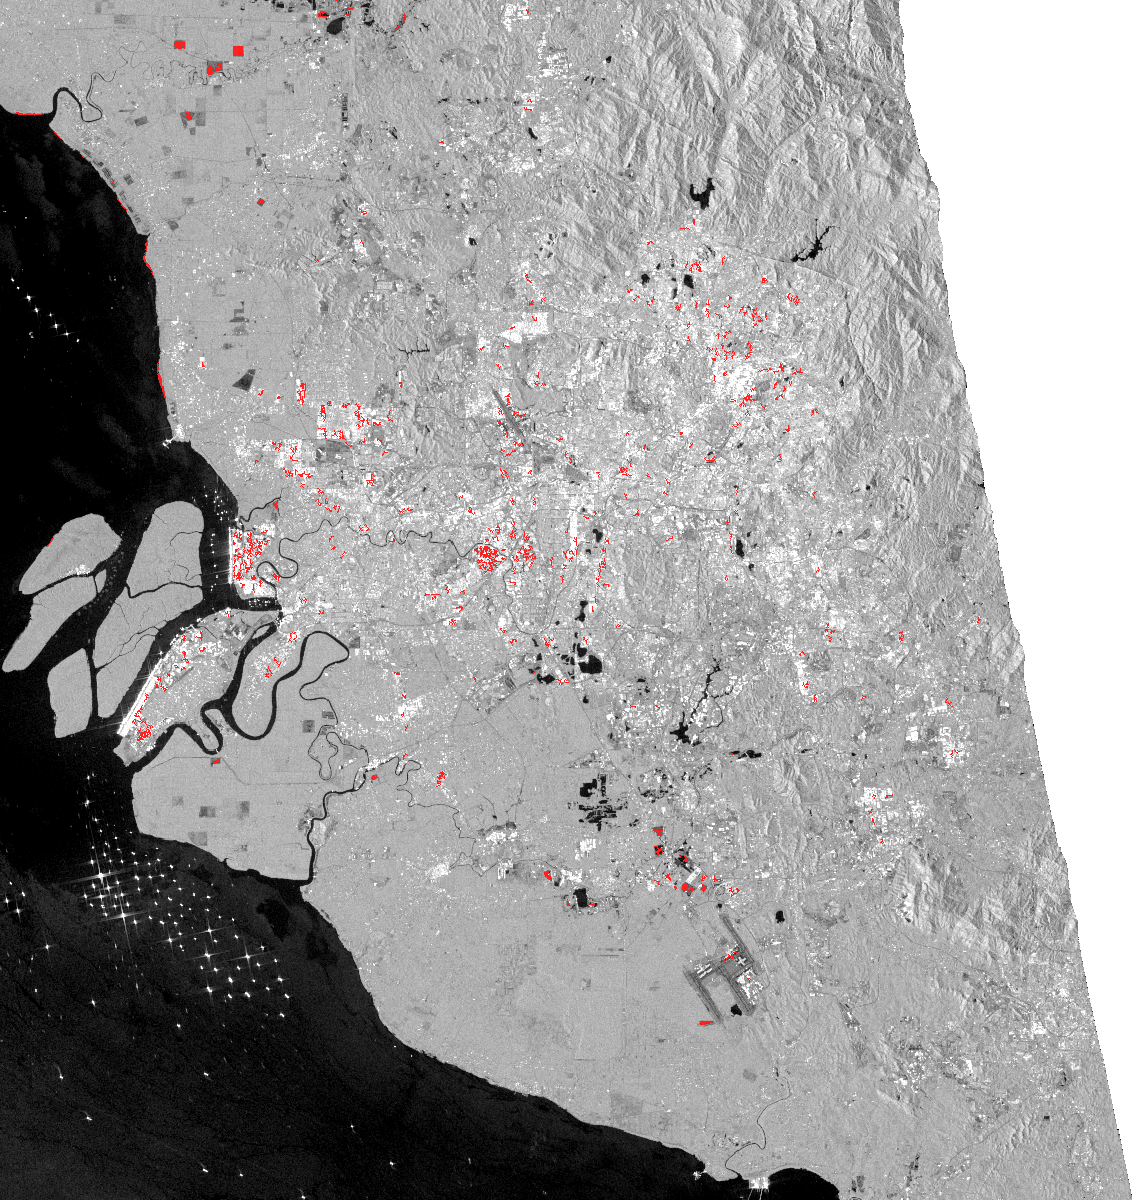

Saved output/stage4_flood_preview_dry_days.png (1,514,253 bytes)


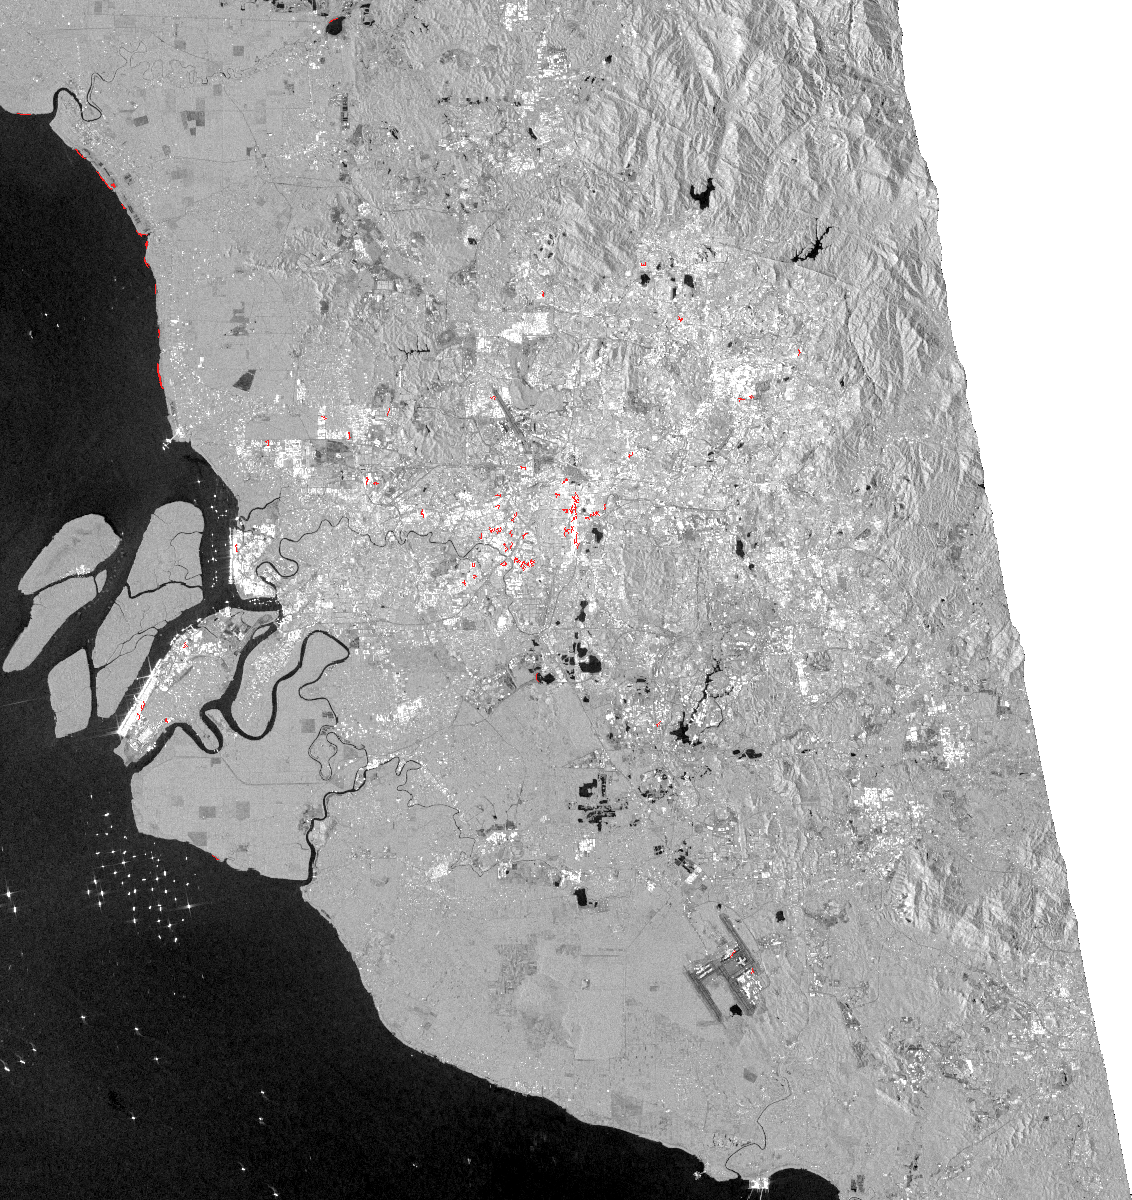

In [ ]:
if MAKE_PREVIEW:
    try:
        import requests
        from IPython.display import Image as IPImage, display
        os.makedirs("output", exist_ok=True)
        def preview(keys, fname):
            bg = layers[keys[0]]["after"].visualize(min=-25, max=0, palette=["000000", "ffffff"])
            m = layers[keys[0]]["F"].Or(layers[keys[1]]["F"])
            red = m.selfMask().visualize(palette=["ff2020"])
            url = ee.ImageCollection([bg, red]).mosaic().getThumbURL(
                {"region": region, "dimensions": 1200, "format": "png", "crs": "EPSG:4326"})
            r = requests.get(url, timeout=300)
            r.raise_for_status()
            with open(fname, "wb") as f:
                f.write(r.content)
            print("Saved", fname, f"({len(r.content):,} bytes)")
            display(IPImage(data=r.content, width=600))
        preview(["a", "b"], "output/stage4_flood_preview_flood_days.png")
        preview(["c", "d"], "output/stage4_flood_preview_dry_days.png")
    except Exception as err:
        print("Preview not made:", type(err).__name__, str(err)[:200])

## Step 7: add up per hexagon

For each hexagon and each of the four comparisons: the share of the hexagon area flagged (`F`), flagged as open water (`W`), flagged as built-up flooding (`U`) and actually seen by the radar (`obs`). Also the built-up share and the usable-ground share. Finished batches are saved in a cache folder, so you can stop and re-run.

In [ ]:
bands = []
for k, L in layers.items():
    bands += [L["F"].rename("F_" + k), L["W"].rename("W_" + k), L["U"].rename("U_" + k), L["observed"].rename("obs_" + k)]
bands += [builtup.rename("builtup"), ok_ground.rename("ok_ground")]
stats_img = ee.Image.cat(bands).toFloat()
STAT_COLS = [b for b in stats_img.bandNames().getInfo()]

settings = {"events": EVENTS, "smooth": SMOOTH_M, "water_max": WATER_MAX_DB, "water_drop": WATER_DROP_DB,
            "bright": BRIGHT_DB, "urban": USE_BUILTUP_RULE, "min_conn": MIN_CONNECTED, "perm": PERM_WATER_PCT,
            "hand": HAND_MAX_M, "slope": SLOPE_MAX_DEG, "scale": SUM_SCALE_M, "dem": dem_used, "v": 2}
sig = hashlib.md5(json.dumps(settings, sort_keys=True).encode()).hexdigest()[:8]
cache = f"data/processed/flood2_batches_{sig}"
os.makedirs(cache, exist_ok=True)

hexes = grid["h3"].tolist()
batches = [hexes[i:i + BATCH_SIZE] for i in range(0, len(hexes), BATCH_SIZE)]
print(f"{len(hexes):,} hexagons in {len(batches)} batches; cache folder {cache}")

t0 = time.time()
done_new = 0
for i, batch in enumerate(batches):
    path = f"{cache}/batch_{i:03d}.json"
    if os.path.exists(path):
        continue
    fc = ee.FeatureCollection([hex_feature(h) for h in batch])
    for attempt in range(4):
        try:
            res = stats_img.reduceRegions(collection=fc, reducer=ee.Reducer.mean(), scale=SUM_SCALE_M, tileScale=4).getInfo()
            break
        except Exception as err:
            print(f"\n  batch {i} attempt {attempt + 1} failed: {type(err).__name__} {str(err)[:120]}")
            time.sleep(5 * (attempt + 1))
    else:
        raise RuntimeError(f"Batch {i} failed 4 times. Re-run this cell to continue from here.")
    rows = [dict(f["properties"]) for f in res["features"]]
    with open(path, "w") as f:
        json.dump(rows, f)
    done_new += 1
    elapsed = time.time() - t0
    left = elapsed / done_new * (len(batches) - i - 1)
    print(f"\r  batch {i + 1}/{len(batches)} done, {elapsed/60:.1f} min so far, about {left/60:.1f} min left   ", end="")
print("\nAll batches ready.")

4,003 hexagons in 17 batches; cache folder data/processed/flood2_batches_d706affb
  batch 17/17 done, 1.5 min so far, about 0.0 min left   
All batches ready.


## Step 8: calibrate, decide and save

Re-run only this step after changing `CHOSEN_RULE` or `HEX_THRESHOLD`.

**Calibration table:** for each threshold, how many hexagons are flagged on the flood days and on the dry control days, for both rules (`both` = flagged on both days of the pair, `either` = at least one). A good threshold flags many hexagons on flood days and almost none on dry days.

**Known places:** the score of the hexagon at each place and the highest score among it and its six neighbours (a point can fall on the edge of a hexagon).

In [ ]:
rows = []
for i in range(len(batches)):
    with open(f"{cache}/batch_{i:03d}.json") as f:
        rows += json.load(f)
fl = pd.DataFrame(rows)
for c in STAT_COLS:
    fl[c] = fl[c].fillna(0).clip(0, 1)
df = grid[["h3", "district", "population"]].merge(fl, on="h3", how="left")
assert len(df) == len(grid) and df["F_a"].notna().all()

# pair scores: share of hexagon area flagged, combined over the two days of a pair
df["flood_either"] = df[["F_a", "F_b"]].max(axis=1)
df["flood_both"] = df[["F_a", "F_b"]].min(axis=1)
df["dry_either"] = df[["F_c", "F_d"]].max(axis=1)
df["dry_both"] = df[["F_c", "F_d"]].min(axis=1)

print("CALIBRATION (hexagons flagged at each threshold; 4,003 hexagons in total)")
cal = []
for T in [0.02, 0.05, 0.10, 0.15, 0.20, 0.30, 0.40, 0.50]:
    cal.append({"threshold": T,
                "flood_both": int((df.flood_both >= T).sum()), "dry_both": int((df.dry_both >= T).sum()),
                "flood_either": int((df.flood_either >= T).sum()), "dry_either": int((df.dry_either >= T).sum()),
                "people_flood_both": int(df.loc[df.flood_both >= T, "population"].sum()),
                "people_flood_either": int(df.loc[df.flood_either >= T, "population"].sum())})
cal = pd.DataFrame(cal)
print(cal.to_string(index=False))
print()
for rule in ["both", "either"]:
    ok = cal[(cal[f"dry_{rule}"] <= np.maximum(2, BASELINE_TOLERANCE * cal[f"flood_{rule}"])) & (cal[f"flood_{rule}"] > 0)]
    if len(ok):
        t = ok.iloc[0]
        print(f"Suggestion for '{rule}': lowest threshold where dry days flag at most {int(BASELINE_TOLERANCE*100)}% as many hexagons: "
              f"{t.threshold:.2f} ({int(t[f'flood_{rule}'])} flood-day hexagons against {int(t[f'dry_{rule}'])} on dry days)")
    else:
        print(f"Suggestion for '{rule}': no threshold in the table separates flood days from dry days well enough")

print("\nKNOWN PLACES (share of hexagon area flagged; max over the hexagon and its neighbours)")
sc = df.set_index("h3")
for name, lon, lat, note in PLACES:
    c = h3.latlng_to_cell(lat, lon, 8)
    ring = [x for x in h3.grid_disk(c, 1) if x in sc.index]
    if c not in sc.index:
        print(f"{name:30s} outside the hexagon grid")
        continue
    print(f"{name:30s} [{note}]  both: {sc.loc[c, 'flood_both']:.2f} (max near {sc.loc[ring, 'flood_both'].max():.2f})   "
          f"either: {sc.loc[c, 'flood_either']:.2f} (max near {sc.loc[ring, 'flood_either'].max():.2f})   "
          f"dry-day either: {sc.loc[c, 'dry_either']:.2f}")

# final decision
df["flood_share"] = df["flood_" + CHOSEN_RULE]
df["flooded"] = df["flood_share"] >= HEX_THRESHOLD
df["flood_share"] = df["flood_share"].round(4)
for c in STAT_COLS + ["flood_either", "flood_both", "dry_either", "dry_both"]:
    df[c] = df[c].round(4)
df.to_parquet("data/processed/hex_flood.parquet", index=False)
with open("data/processed/flood_meta.json", "w") as f:
    json.dump({"settings": settings, "chosen_rule": CHOSEN_RULE, "hex_threshold": HEX_THRESHOLD,
               "areas_km2": diag, "calibration": cal.to_dict("records"), "cache": cache}, f, indent=1)

print(f"\nFINAL: rule '{CHOSEN_RULE}', threshold {HEX_THRESHOLD:.2f}")
m = df["flooded"]
print(f"Flooded hexagons: {m.sum():,} of {len(df):,}; people living in them: {int(df.loc[m, 'population'].sum()):,} "
      f"({100 * df.loc[m, 'population'].sum() / df['population'].sum():.1f}% of the Klang Valley)")
print(f"Hexagons where the radar saw less than half the area on a flood day: {(df[['obs_a','obs_b']].min(axis=1) < 0.5).sum():,}")
by = df.groupby("district").apply(lambda d: pd.Series({
    "hexagons": len(d), "flooded": int(d["flooded"].sum()),
    "people_flooded": int(d.loc[d["flooded"], "population"].sum()),
    "pct_of_people": round(100 * d.loc[d["flooded"], "population"].sum() / max(d["population"].sum(), 1), 1)}))
print(by.to_string())
print("\nSaved data/processed/hex_flood.parquet and flood_meta.json")

CALIBRATION (hexagons flagged at each threshold; 4,003 hexagons in total)
 threshold  flood_both  dry_both  flood_either  dry_either  people_flood_both  people_flood_either
      0.02          66        10           563          83             174199              2671954
      0.05          18         0           213          30              46904               987501
      0.10           5         0            45           8              21592               148603
      0.15           2         0            15           1               7876                37684
      0.20           0         0             6           0                  0                15000
      0.30           0         0             3           0                  0                 4493
      0.40           0         0             0           0                  0                    0
      0.50           0         0             0           0                  0                    0

Suggestion for 'both': lowest thre

___
**END**